# Module 2 — Credit Risk: Corporate & Retail Lending

**Business question:** Which loans should NovaFin approve, review or reject?

> **Data → ML probability of default → PD & Expected Credit Loss → Approve / Review / Reject**

**Key assumptions:**
- `Loan_Amount` / `Collateral_Value` are read as **INR (rupees)** — loans of ~10 lakh are realistic, whereas reading them as *lakh* implies absurd crore-scale retail loans. Money is reported in **INR crore** (÷1e7) for the board.
- Each row is one loan; `Customer_ID` is the loan identifier (unique per row).
- **ECL = PD × LGD × EAD**, with **LGD = 40%**, **EAD = Loan_Amount** (per the brief).
- Because PD feeds directly into ECL, we prioritise **probability calibration**: models are trained **without** class-weight balancing (which would inflate PDs) despite the ~20% imbalance.
- PD bands (justified, not blindly adopted): **<5% Low · 5–15% Medium · 15–30% High · >30% Very High**.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "src"))
sys.path.insert(0, str(Path.cwd() / "src"))

from novafin.config import SEED, apply_plot_style, output_dir
from novafin.data import load_loans
from novafin.evaluation import classification_scores, compare_models
from novafin.finance import expected_credit_loss

apply_plot_style()
OUT = output_dir("module2")
TARGET, LGD, CRORE = "Default_Flag", 0.40, 1e7
print("Seed:", SEED, "| outputs ->", OUT)

Seed: 42 | outputs -> C:\Users\rahul\Desktop\Sheetal\MLF\Capstone project\outputs\module2


In [2]:
def engineer_features(df):
    df = df.copy()
    df["Loan_to_Income"] = df["Loan_Amount"] / df["Annual_Income"]
    df["Collateral_Coverage"] = df["Collateral_Value"] / df["Loan_Amount"]
    df["Total_Debt_to_Income"] = (df["Existing_Loan"] + df["Loan_Amount"]) / df["Annual_Income"]
    return df

df = engineer_features(load_loans())
print(df.shape)
df.head()

(5000, 17)


,Customer_ID,Customer_Type,Annual_Income,Employment_Length,Debt_to_Income,Credit_Score,Existing_Loan,Loan_Amount,Loan_Term_Months,Interest_Rate,Collateral_Value,Past_Default,Sector_Risk,Default_Flag,Loan_to_Income,Collateral_Coverage,Total_Debt_to_Income
0,200001,Corporate,939967.04,29,0.248,698,1009401.25,1968503.82,12,8.96,2690085.58,0,65.31,0,2.094226,1.366564,3.168095
1,200002,Retail,1629687.82,2,0.150,747,986482.96,1932554.81,12,7.82,2542892.81,0,33.98,0,1.185844,1.315819,1.791164
2,200003,Corporate,1971716.74,18,0.300,718,1822182.57,815975.44,60,7.13,1202025.19,0,55.13,0,0.413840,1.473114,1.338001
3,200004,Corporate,1848108.58,8,0.082,657,1169299.09,3855380.75,36,12.97,5571538.48,1,75.27,0,2.086122,1.445133,2.718823
4,200005,Retail,673064.61,27,0.111,544,383728.34,749360.88,36,9.18,1272953.05,0,55.35,0,1.113357,1.698718,1.683478


## Task 1 — Exploratory Data Analysis

Default rate is ~20%. We look at how it varies with the classic credit drivers: credit score, debt-to-income, past default and customer type.

In [3]:
print(f"Default rate: {df[TARGET].mean():.1%}  ({df[TARGET].sum()} defaults / {len(df)} loans)")
print("\nDefault rate by Customer_Type:"); print(df.groupby('Customer_Type')[TARGET].mean().round(3))
print("\nDefault rate by Past_Default:"); print(df.groupby('Past_Default')[TARGET].mean().round(3))

Default rate: 19.9%  (997 defaults / 5000 loans)

Default rate by Customer_Type:
Customer_Type
Corporate    0.200
Retail       0.199
Name: Default_Flag, dtype: float64

Default rate by Past_Default:
Past_Default
0    0.177
1    0.378
Name: Default_Flag, dtype: float64


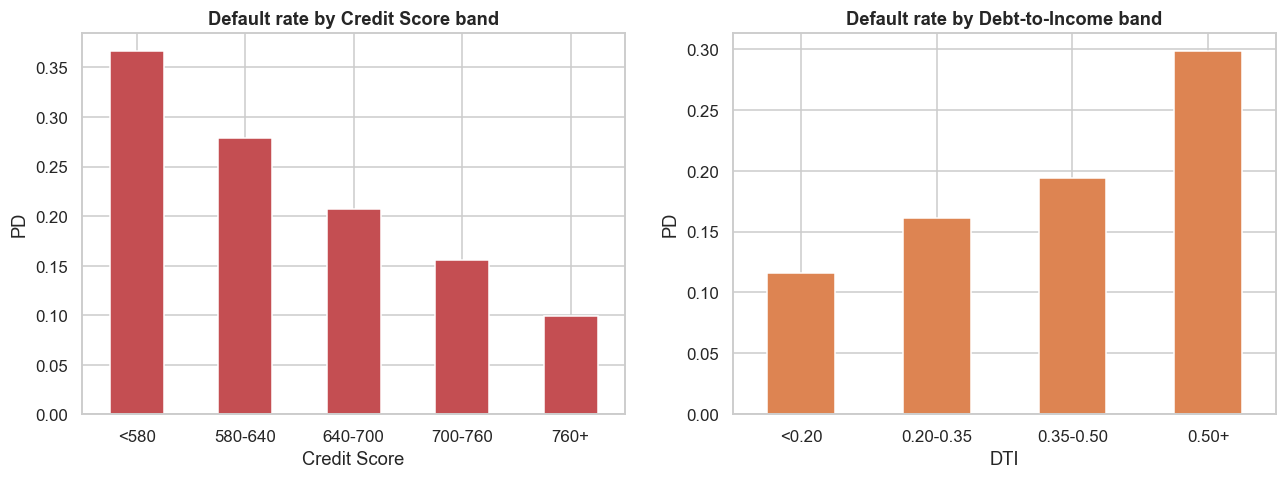

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
score_bins = pd.cut(df['Credit_Score'], bins=[0,580,640,700,760,900],
                    labels=['<580','580-640','640-700','700-760','760+'])
df.groupby(score_bins, observed=True)[TARGET].mean().plot(kind='bar', ax=ax[0], color='#C44E52')
ax[0].set(title='Default rate by Credit Score band', ylabel='PD', xlabel='Credit Score'); ax[0].tick_params(axis='x', rotation=0)
dti_bins = pd.cut(df['Debt_to_Income'], bins=[0,0.2,0.35,0.5,1.0], labels=['<0.20','0.20-0.35','0.35-0.50','0.50+'])
df.groupby(dti_bins, observed=True)[TARGET].mean().plot(kind='bar', ax=ax[1], color='#DD8452')
ax[1].set(title='Default rate by Debt-to-Income band', ylabel='PD', xlabel='DTI'); ax[1].tick_params(axis='x', rotation=0)
fig.savefig(OUT / 'eda_default_drivers.png'); plt.show()

## Task 1/2 — Predict Probability of Default

Four models compared with stratified 5-fold CV, scored on **out-of-fold** probabilities (leakage-free, and reused as each borrower's PD). Metrics emphasise ROC-AUC / PR-AUC over accuracy given the imbalance. **Precision/Recall/F1 are reported at the default 0.5 cut only for reference — the lending decision below uses PD *bands*, not a 0.5 threshold.** We also check calibration (mean predicted PD vs actual default rate).

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

CATEGORICAL = ['Customer_Type']
NUMERIC = ['Annual_Income','Employment_Length','Debt_to_Income','Credit_Score','Existing_Loan',
           'Loan_Amount','Loan_Term_Months','Interest_Rate','Collateral_Value','Past_Default',
           'Sector_Risk','Loan_to_Income','Collateral_Coverage','Total_Debt_to_Income']

def make_prep():
    return ColumnTransformer([('num', StandardScaler(), NUMERIC),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL)])

X, y = df[NUMERIC + CATEGORICAL], df[TARGET]
models = {
    'LogisticRegression': LogisticRegression(max_iter=2000),
    'RandomForest': RandomForestClassifier(n_estimators=400, random_state=SEED),
    'GradientBoosting': GradientBoostingClassifier(random_state=SEED),
    'XGBoost': XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05,
                             subsample=0.9, colsample_bytree=0.9, eval_metric='logloss', random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results, oof = {}, {}
for name, clf in models.items():
    pipe = Pipeline([('prep', make_prep()), ('clf', clf)])
    proba = cross_val_predict(pipe, X, y, cv=cv, method='predict_proba')[:, 1]
    results[name] = classification_scores(y, proba); oof[name] = proba
table = compare_models(results); table.to_csv(OUT / 'model_comparison.csv'); table

,ROC_AUC,PR_AUC,Precision,Recall,F1
LogisticRegression,0.7323,0.4045,0.5467,0.1234,0.2013
GradientBoosting,0.7174,0.3779,0.5142,0.1635,0.2481
XGBoost,0.7069,0.3670,0.4593,0.1585,0.2356
RandomForest,0.7046,0.3720,0.5073,0.1394,0.2187


In [6]:
best = table.index[0]
pd_series = pd.Series(oof[best], index=df.index, name='Predicted_PD')
print('Best model:', best)
print(f'Calibration: mean predicted PD {pd_series.mean():.3f} vs actual default rate {y.mean():.3f}')

Best model: LogisticRegression
Calibration: mean predicted PD 0.200 vs actual default rate 0.199


> Calibration is essentially exact (mean PD ≈ actual default rate), which is why we deliberately avoided class-weighting — the PDs can be trusted in the ECL formula.

Background dataset has 1000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1000 when initializing the masker.


C:\Users\rahul\AppData\Local\Temp\ipykernel_21056\1575652708.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(values, X_trans, feature_names=feature_names, show=False)


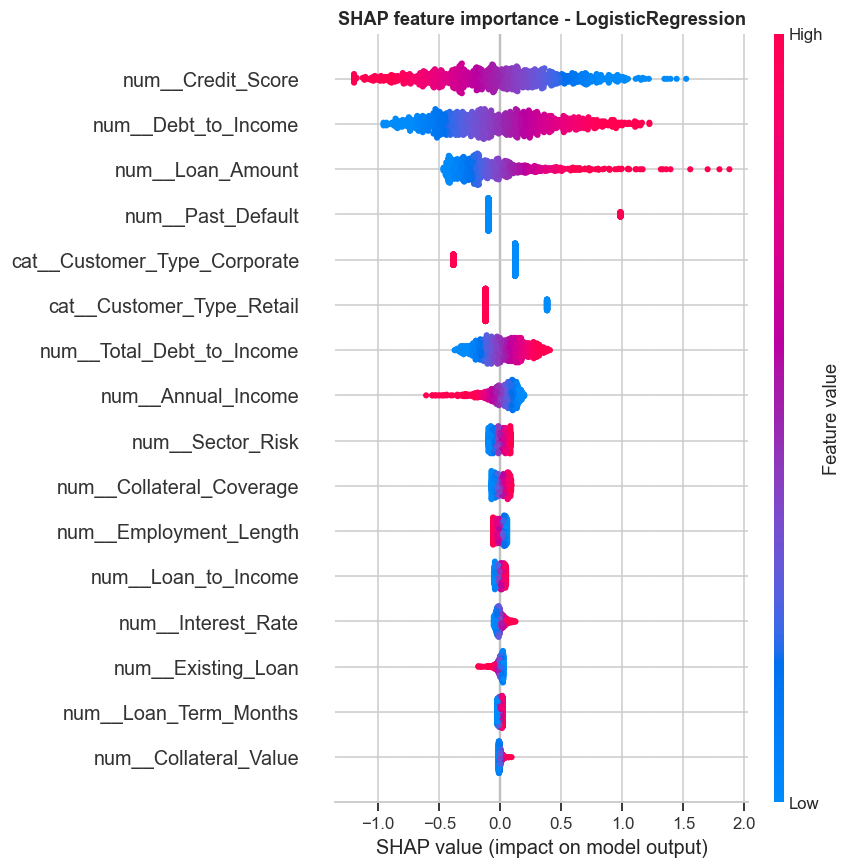

In [7]:
import shap
best_pipe = Pipeline([('prep', make_prep()), ('clf', models[best])]).fit(X, y)
prep, clf = best_pipe.named_steps['prep'], best_pipe.named_steps['clf']
Xs = X.sample(min(1000, len(X)), random_state=SEED)
X_trans = prep.transform(Xs); feature_names = prep.get_feature_names_out()
explainer = shap.LinearExplainer(clf, X_trans) if best == 'LogisticRegression' else shap.TreeExplainer(clf)
sv = explainer(X_trans)
values = sv.values[:, :, 1] if sv.values.ndim == 3 else sv.values
shap.summary_plot(values, X_trans, feature_names=feature_names, show=False)
plt.title(f'SHAP feature importance - {best}'); plt.savefig(OUT / 'shap_summary.png', bbox_inches='tight'); plt.show()

## Task 2/3 — PD bands, ECL and lending decision

**Decision rule** (risk appetite tightens as PD rises; collateral cushions loss):
- **Very High** PD → Reject
- **Low** PD → Approve
- **Medium** PD → Approve if collateral ≥ loan, else Review
- **High** PD → Review only if strongly over-collateralised (≥1.5×), else Reject

In [8]:
def risk_category(p):
    return 'Low' if p < 0.05 else 'Medium' if p < 0.15 else 'High' if p < 0.30 else 'Very High'

def lending_decision(rc, cov):
    if rc == 'Very High': return 'Reject'
    if rc == 'Low': return 'Approve'
    if rc == 'Medium': return 'Approve' if cov >= 1.0 else 'Review'
    return 'Review' if cov >= 1.5 else 'Reject'

out = pd.DataFrame({
    'Loan_ID': df['Customer_ID'],
    'Customer_Type': df['Customer_Type'],
    'Loan_Amount': df['Loan_Amount'].round(2),
    'Collateral_Coverage': (df['Collateral_Value'] / df['Loan_Amount']).round(2),
    'Predicted_PD': pd_series.round(4),
})
out['Risk_Category'] = out['Predicted_PD'].apply(risk_category)
out['ECL'] = expected_credit_loss(out['Predicted_PD'], df['Loan_Amount'], LGD).round(2)
out['Decision'] = [lending_decision(rc, cov) for rc, cov in zip(out['Risk_Category'], out['Collateral_Coverage'])]
out[['Loan_ID','Predicted_PD','Risk_Category']].to_csv(OUT / 'pd_risk_categories.csv', index=False)
out.to_csv(OUT / 'loan_decisions.csv', index=False)
out.head(10)

,Loan_ID,Customer_Type,Loan_Amount,Collateral_Coverage,Predicted_PD,Risk_Category,ECL,Decision
0,200001,Corporate,1968503.82,1.37,0.1648,High,129763.77,Reject
1,200002,Retail,1932554.81,1.32,0.0509,Medium,39346.82,Approve
2,200003,Corporate,815975.44,1.47,0.0606,Medium,19779.24,Approve
3,200004,Corporate,3855380.75,1.45,0.4949,Very High,763211.17,Reject
4,200005,Retail,749360.88,1.70,0.1734,High,51975.67,Review
5,200006,Retail,2065598.75,1.98,0.1720,High,142113.19,Review
6,200007,Retail,576722.70,1.59,0.1815,High,41870.07,Review
7,200008,Corporate,2015226.77,1.16,0.2564,High,206681.66,Reject
8,200009,Retail,1351384.69,1.19,0.3105,Very High,167841.98,Reject
9,200010,Retail,331370.37,0.54,0.3006,Very High,39843.97,Reject


In [9]:
print('Risk category distribution:')
print(out['Risk_Category'].value_counts().reindex(['Low','Medium','High','Very High']))
print('\nDecision distribution:'); print(out['Decision'].value_counts())
print('\nExposure and ECL by decision (INR crore):')
out.groupby('Decision').agg(Loans=('Loan_ID','count'),
                            Exposure_cr=('Loan_Amount', lambda s: s.sum()/CRORE),
                            ECL_cr=('ECL', lambda s: s.sum()/CRORE)).round(1)

Risk category distribution:
Risk_Category
Low           335
Medium       1973
High         1680
Very High    1012
Name: count, dtype: int64

Decision distribution:
Decision
Reject     2065
Approve    1615
Review     1320
Name: count, dtype: int64

Exposure and ECL by decision (INR crore):


,Loans,Exposure_cr,ECL_cr
Decision,,,
Approve,1615,145.1,5.4
Reject,2065,343.7,47.7
Review,1320,150.8,9.8


## Executive summary

The PD model plus a collateral-aware decision rule lets NovaFin **lend selectively**: the approved book carries a materially lower expected loss rate than the portfolio as a whole. This approved exposure and its ECL are the credit-risk inputs to the Module 11 capital allocation.

In [10]:
ap = out[out['Decision'] == 'Approve']; total_ecl = out['ECL'].sum()
print(f"Best model: {best}")
print(f"APPROVE: {len(ap)} of {len(out)} loans ({len(ap)/len(out):.0%})")
print(f"Approved exposure: INR {ap['Loan_Amount'].sum()/CRORE:,.0f} crore")
print(f"ECL on approved book: INR {ap['ECL'].sum()/CRORE:,.1f} crore ({ap['ECL'].sum()/ap['Loan_Amount'].sum():.2%} of exposure)")
print(f"Portfolio-wide ECL if all lent: INR {total_ecl/CRORE:,.0f} crore ({total_ecl/out['Loan_Amount'].sum():.2%} of exposure)")

Best model: LogisticRegression
APPROVE: 1615 of 5000 loans (32%)
Approved exposure: INR 145 crore
ECL on approved book: INR 5.4 crore (3.74% of exposure)
Portfolio-wide ECL if all lent: INR 63 crore (9.83% of exposure)
